In [1]:
#Exploratory Data Analysis 

# Importing required libraries.

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import binom

In [2]:
#Loading the Dataset 

df = pd.read_csv("hour.csv")

In [3]:
#First Look at the data

df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
df.tail()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61
17378,17379,2012-12-31,1,1,12,23,0,1,1,1,0.26,0.2727,0.65,0.1343,12,37,49


In [5]:
#Number of Rows and Columns 

df.shape

(17379, 17)

In [6]:
#Types of data

df.dtypes

instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

In [7]:
#checking whether it is necessary to clean the data

df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [8]:
#checking for duplicate rows

print(df.duplicated().sum())

0


In [9]:
#check descriptive statistics

df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [10]:
#Dropping irrelevant column "instant"

df= df.drop(["instant"], axis=1)



In [11]:
df.head()

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [12]:
df.shape

(17379, 16)

In [13]:
#verify data consistency in this section: "cnt: count of total rental bikes, including both casual and registered users"

df["casual"] + df["registered"]

0         16
1         40
2         32
3         13
4          1
        ... 
17374    119
17375     89
17376     90
17377     61
17378     49
Length: 17379, dtype: int64

In [14]:
df["cnt"] != df["casual"] + df["registered"]

0        False
1        False
2        False
3        False
4        False
         ...  
17374    False
17375    False
17376    False
17377    False
17378    False
Length: 17379, dtype: bool

In [15]:
(df["cnt"] != df["casual"] + df["registered"]).sum()

0

In [16]:
#Detecting Outliers

Q1 = df["cnt"].quantile(0.25)
Q3 = df["cnt"].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

outliers = df[df["cnt"] > upper_limit]

print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(outliers))

Upper limit: 642.5
Number of potential outliers: 505


In [17]:
#Analysing the "cnt" variable

df["cnt"].describe()

count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64

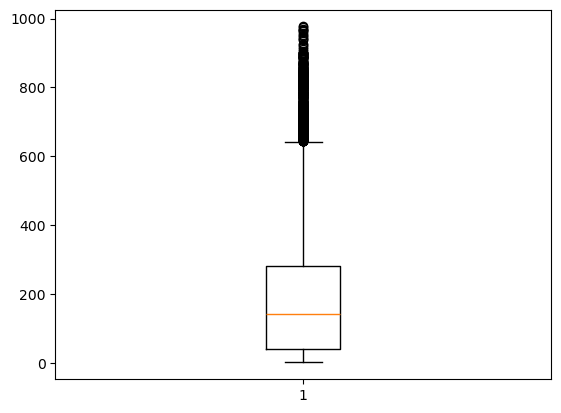

In [19]:
#Draw boxplot of cnt 
plt.boxplot(df["cnt"])
plt.show()

In [20]:
# Creating a correlation Heatmap 

numeric_df = df.select_dtypes(include="number")

numeric_df.head()



,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [21]:
correlation_matrix = numeric_df.corr()

correlation_matrix

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
season,1.000000,-0.010742,0.830386,-0.006117,-0.009585,-0.002335,0.013743,-0.014524,0.312025,0.319380,0.150625,-0.149773,0.120206,0.174226,0.178056
yr,-0.010742,1.000000,-0.010473,-0.003867,0.006692,-0.004485,-0.002196,-0.019157,0.040913,0.039222,-0.083546,-0.008740,0.142779,0.253684,0.250495
mnth,0.830386,-0.010473,1.000000,-0.005772,0.018430,0.010400,-0.003477,0.005400,0.201691,0.208096,0.164411,-0.135386,0.068457,0.122273,0.120638
hr,-0.006117,-0.003867,-0.005772,1.000000,0.000479,-0.003498,0.002285,-0.020203,0.137603,0.133750,-0.276498,0.137252,0.301202,0.374141,0.394071
holiday,-0.009585,0.006692,0.018430,0.000479,1.000000,-0.102088,-0.252471,-0.017036,-0.027340,-0.030973,-0.010588,0.003988,0.031564,-0.047345,-0.030927
weekday,-0.002335,-0.004485,0.010400,-0.003498,-0.102088,1.000000,0.035955,0.003311,-0.001795,-0.008821,-0.037158,0.011502,0.032721,0.021578,0.026900
workingday,0.013743,-0.002196,-0.003477,0.002285,-0.252471,0.035955,1.000000,0.044672,0.055390,0.054667,0.015688,-0.011830,-0.300942,0.134326,0.030284
weathersit,-0.014524,-0.019157,0.005400,-0.020203,-0.017036,0.003311,0.044672,1.000000,-0.102640,-0.105563,0.418130,0.026226,-0.152628,-0.120966,-0.142426
temp,0.312025,0.040913,0.201691,0.137603,-0.027340,-0.001795,0.055390,-0.102640,1.000000,0.987672,-0.069881,-0.023125,0.459616,0.335361,0.404772
atemp,0.319380,0.039222,0.208096,0.133750,-0.030973,-0.008821,0.054667,-0.105563,0.987672,1.000000,-0.051918,-0.062336,0.454080,0.332559,0.400929


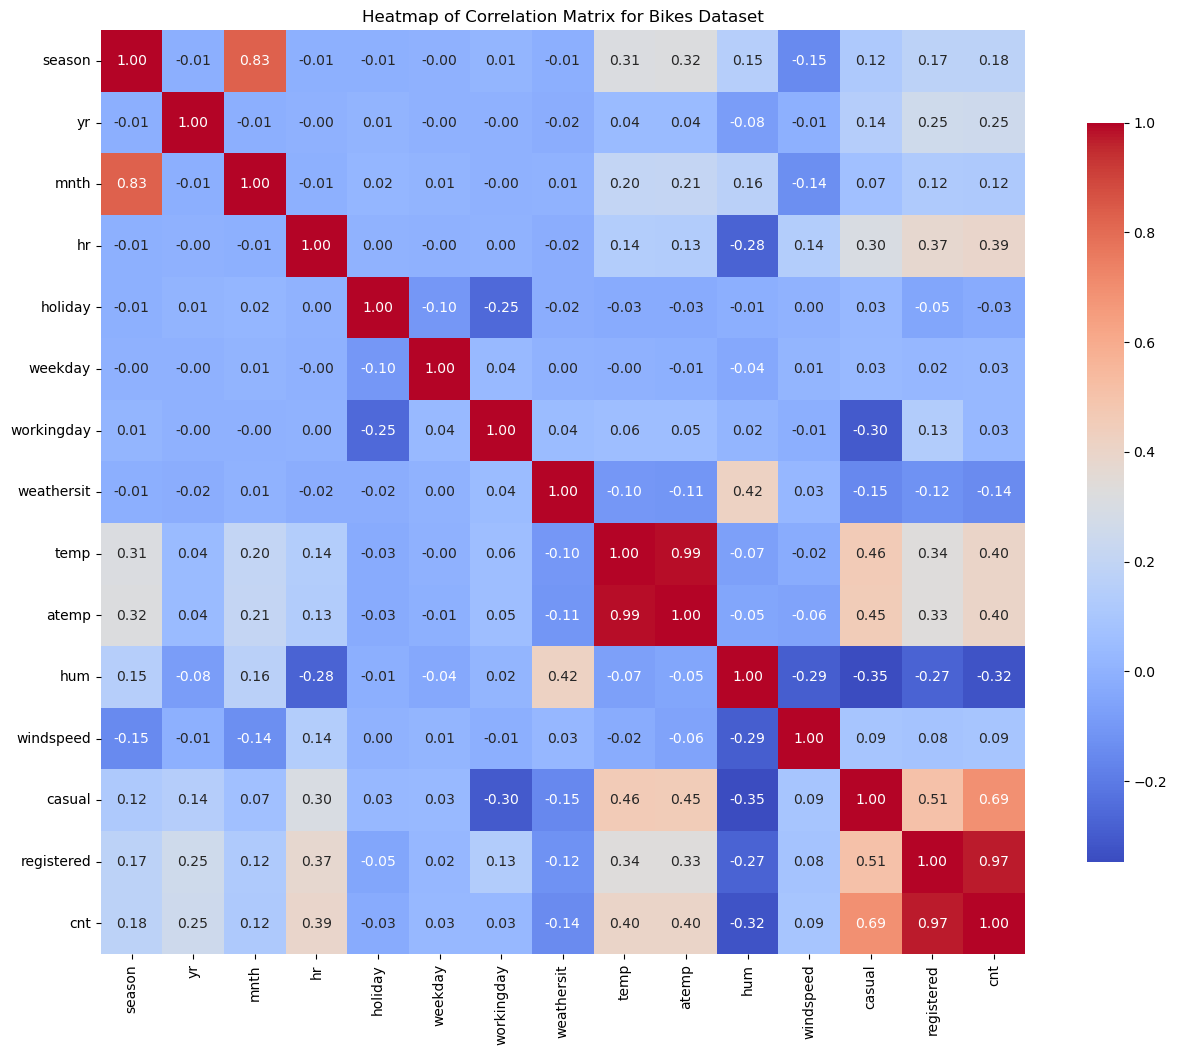

In [35]:
plt.figure(figsize=(16, 12))

sns.heatmap(correlation_matrix,annot=True,fmt=".2f",cmap="coolwarm",square=True,cbar_kws={"shrink": .8})
plt.title('Heatmap of Correlation Matrix for Bikes Dataset')   
plt.show()

First of all, I would like to know which station has the highest number of bicycle users.

To this end, it is useful to use a "season" column and a "cnt" column, as the former represents the season and the latter the total number of rentals per hour.

In [37]:
# Total bike rentals by season
season_rentals = df.groupby("season")["cnt"].sum()

print(season_rentals)

season
1     471348
2     918589
3    1061129
4     841613
Name: cnt, dtype: int64



With this result, we know that station "3," or "summer," has a higher number of rentals per hour than the other stations.

Calculating the mean would also be useful.

In [43]:
season_average = df.groupby("season")["cnt"].mean()
print(season_average)

season
1    111.114569
2    208.344069
3    236.016237
4    198.868856
Name: cnt, dtype: float64


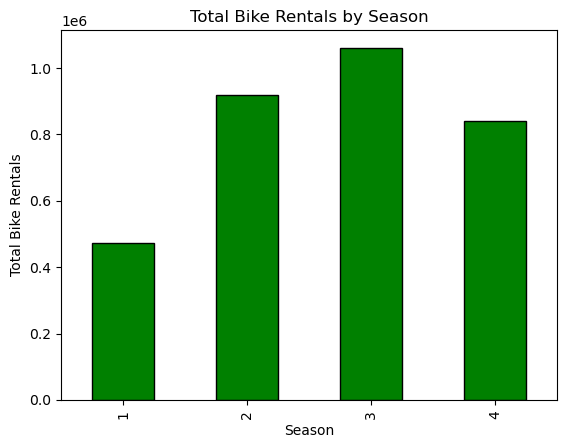

In [39]:
#Graphically representing the use of bicycles during the different seasons of the year.
season_rentals.plot(kind="bar", color="green", edgecolor="black")

plt.title("Total Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Total Bike Rentals")
plt.show()


Starting with binomial distribution 

What is the probability that 5 out of every 10 randomly selected rentals during the summer will be made by casual users?

In [23]:
#dataset for summer 

summer_df = df[df["season"] == 2]

In [24]:
summer_df.head()

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
1807,2011-03-21,2,0,3,0,0,1,1,3,0.34,0.303,0.66,0.3881,2,11,13
1808,2011-03-21,2,0,3,1,0,1,1,2,0.34,0.303,0.71,0.3881,1,6,7
1809,2011-03-21,2,0,3,2,0,1,1,2,0.34,0.303,0.71,0.3284,1,5,6
1810,2011-03-21,2,0,3,3,0,1,1,2,0.34,0.303,0.71,0.3284,0,1,1
1811,2011-03-21,2,0,3,5,0,1,1,1,0.32,0.303,0.81,0.2985,1,1,2


In [25]:
#Numbers of rows in Summer 
summer_df.shape[0]

4409

In [26]:
#Numbers of casual users 
summer_df["casual"].sum()

203522

In [27]:
summer_df["cnt"].sum()

918589

In [28]:
#Calculating P for the formula 
p = summer_df["casual"].sum() / summer_df["cnt"].sum()
p

0.22155936985964342

aproximadamente 22,16 % de los alquileres de verano son casual.

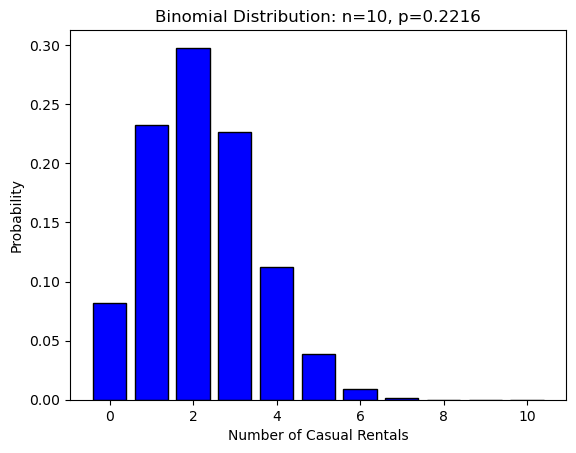

In [34]:
n= 10 #Number of randomly selected rentals 
p= 0.2216 #Probability of a casual rental during summer 
k= np.arange(0,n+1) #Possible number of casual rentals 

# Binomial probability mass function (pmf)
binom_pmf= binom.pmf(k,n,p)

#plot the binomial distribution
plt.bar(k, binom_pmf, color="blue", edgecolor="black")
plt.title("Binomial Distribution: n=10, p=0.2216")
plt.xlabel("Number of Casual Rentals")
plt.ylabel("Probability")
plt.show()



Starting with Poisson Distribution 

What is the probability of observing exactly 5 casual bike rentals in one hour during the summer?